In [1]:
!pip install gwpy gwosc
!pip install wolframalpha wolframclient
!pip install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 315.5/315.5 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.1/131.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 39.9 MB/s eta 0:00:00
  Attempting uninstall: cryptography
    Found existing installation: cryptography 43.0.3
    Uninstalling cryptography-43.0.3:
      Successfully uninstalled cryptography-43.0.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyopenssl 24.2.1 requires cryptography<44,>=41.0.5, but you have cryptography 46.0.3 which is incompatible.
pydrive2 1.21.3 requires cryptography<44, but you have cryptography 46.0.3 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 791

In [2]:
# 필요 패키지 라이브러리 import
from gwpy.timeseries import TimeSeries
import matplotlib.pyplot as plt
import numpy as np
from wolframclient.evaluation import WolframLanguageSession
from wolframclient.language import wl, wlexpr
from wolframclient.exception import WolframLanguageException
from scipy.signal import firwin, filtfilt

In [3]:
# 사용할 데이터 세팅
gps_event = 1126259462  # GW150914 event time
duration = 16
event_start = gps_event - duration/2
event_end = gps_event + duration/2
h1 = TimeSeries.fetch_open_data('H1', event_start, event_end, sample_rate=4096)
l1 = TimeSeries.fetch_open_data('L1', event_start, event_end, sample_rate=4096)

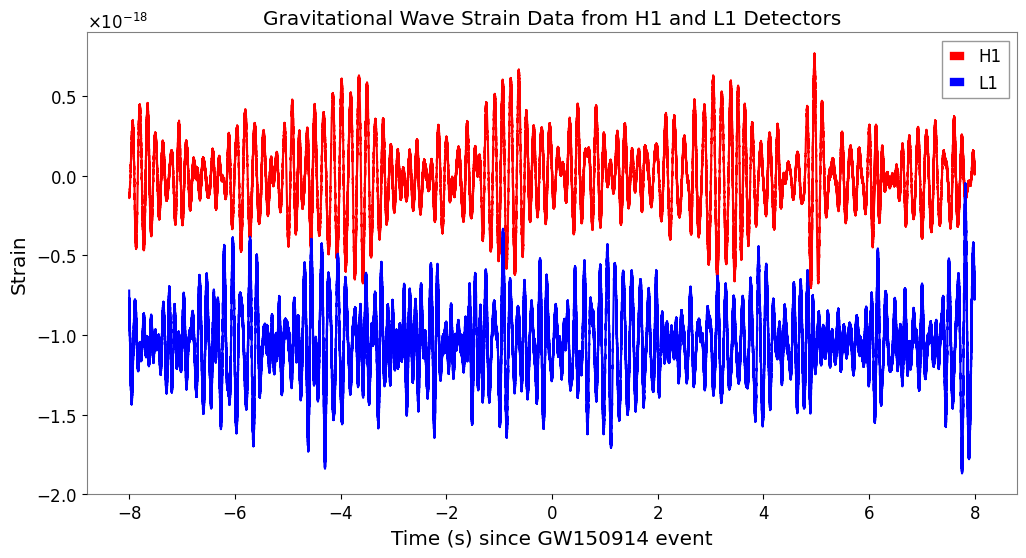

In [37]:
# strain 데이터 이미지 확인
t = h1.times.value - gps_event
h1_strain = h1.value
l1_strain = l1.value

plt.figure(figsize=(12, 6))
plt.plot(t, h1_strain, label='H1', color='red')
plt.plot(t, l1_strain, label='L1', color='blue')
plt.title('Gravitational Wave Strain Data from H1 and L1 Detectors')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('Strain')
plt.legend()
plt.grid()
plt.show()

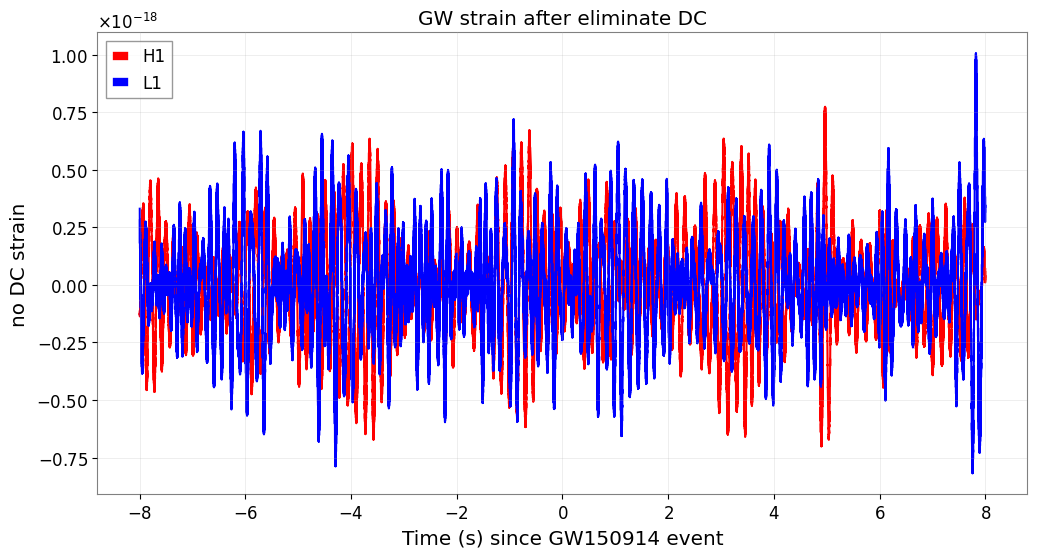

In [38]:
# DC 제거
t = h1.times.value - gps_event
h1_org = h1.copy()
l1_org = l1.copy()

h1_dc = h1_org.detrend('constant')
l1_dc = l1_org.detrend('constant')

plt.figure(figsize=(12, 6))
plt.plot(t, h1_dc, label='H1', color='red')
plt.plot(t, l1_dc, label='L1', color='blue')
plt.title('GW strain after eliminate DC')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('no DC strain')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

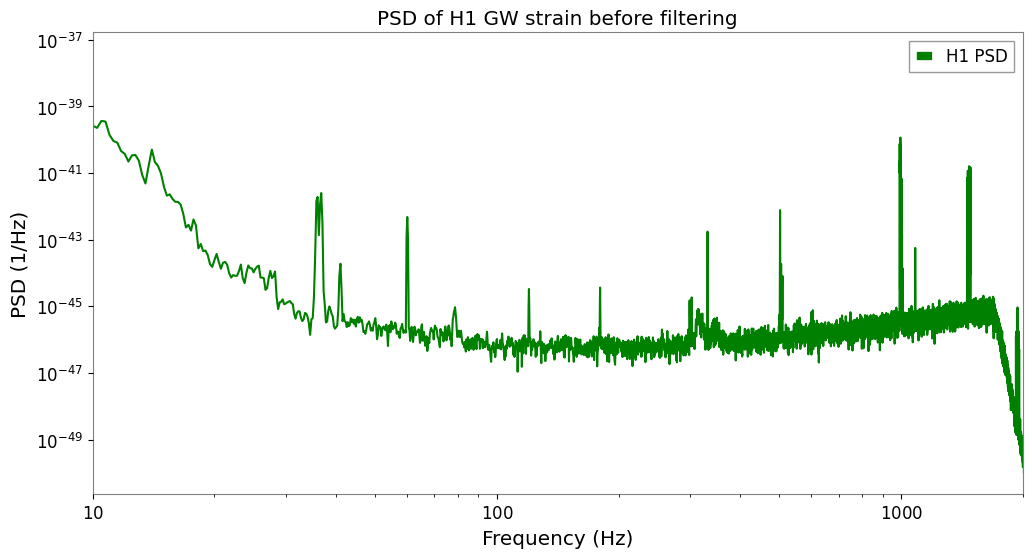

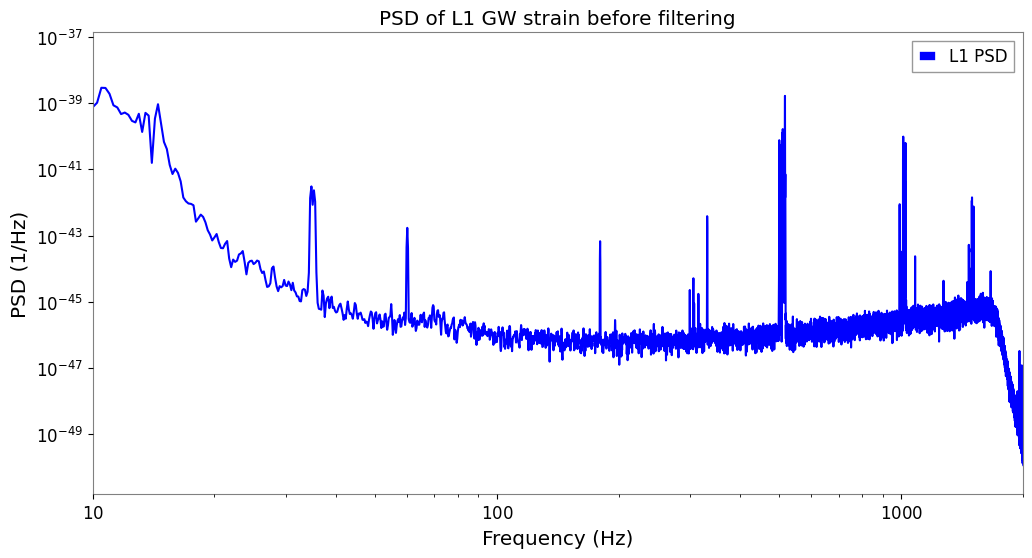

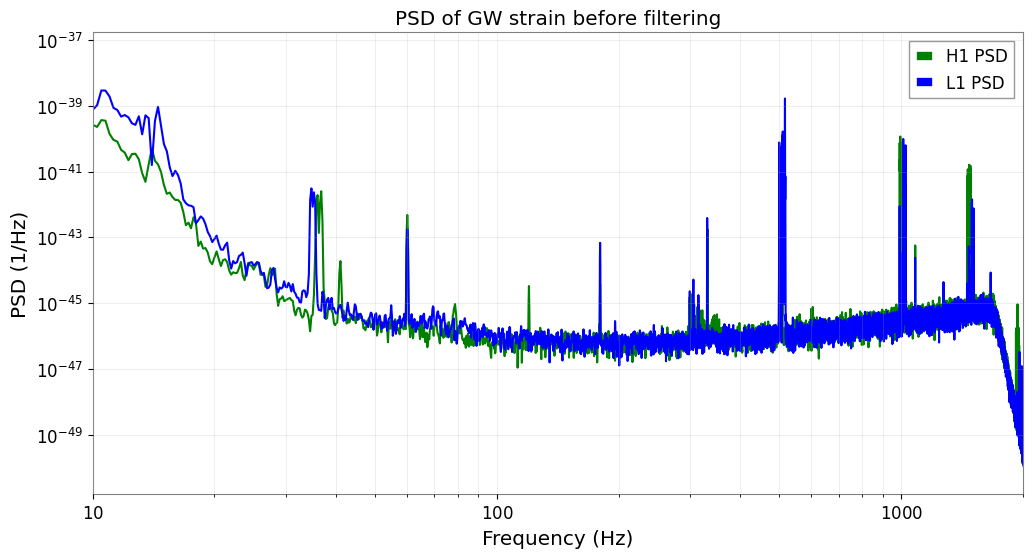

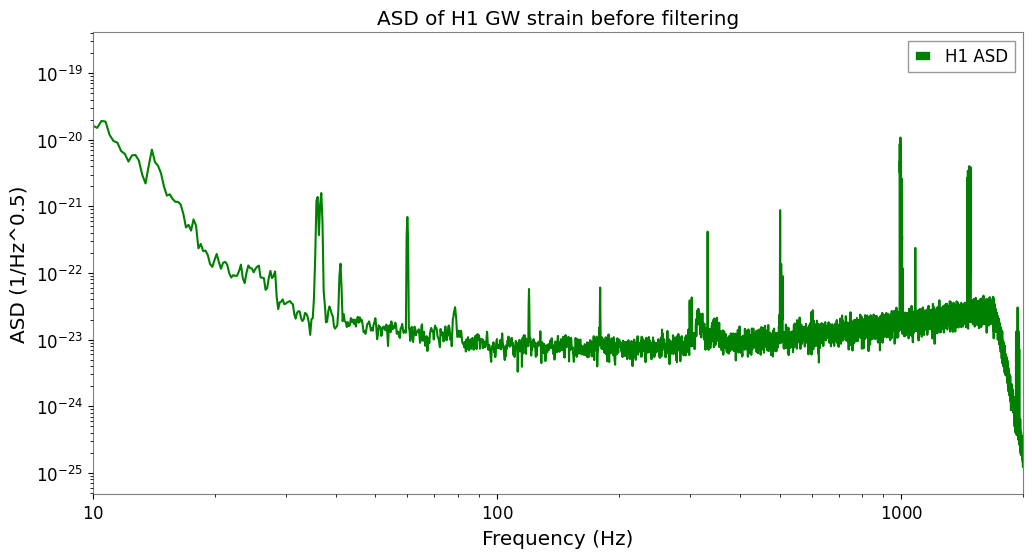

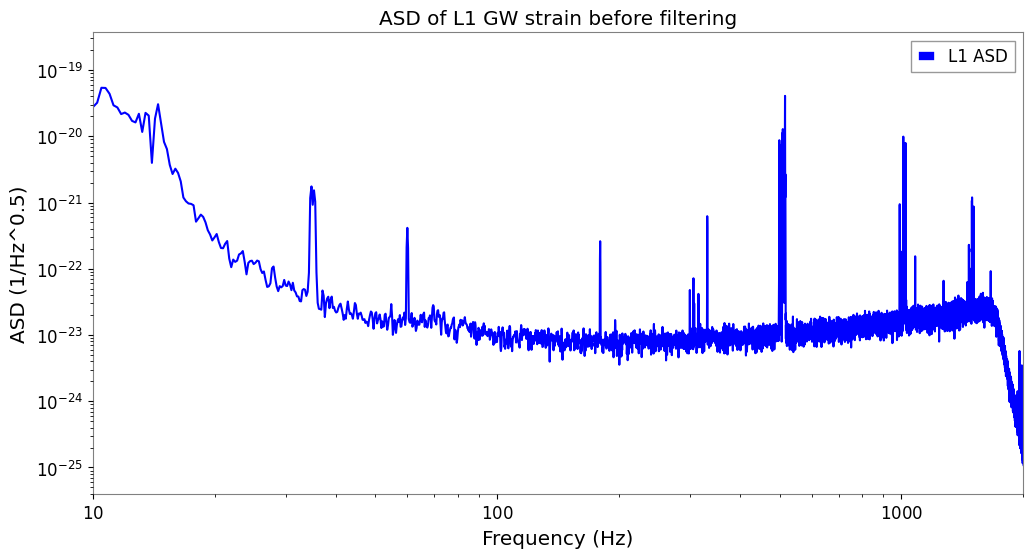

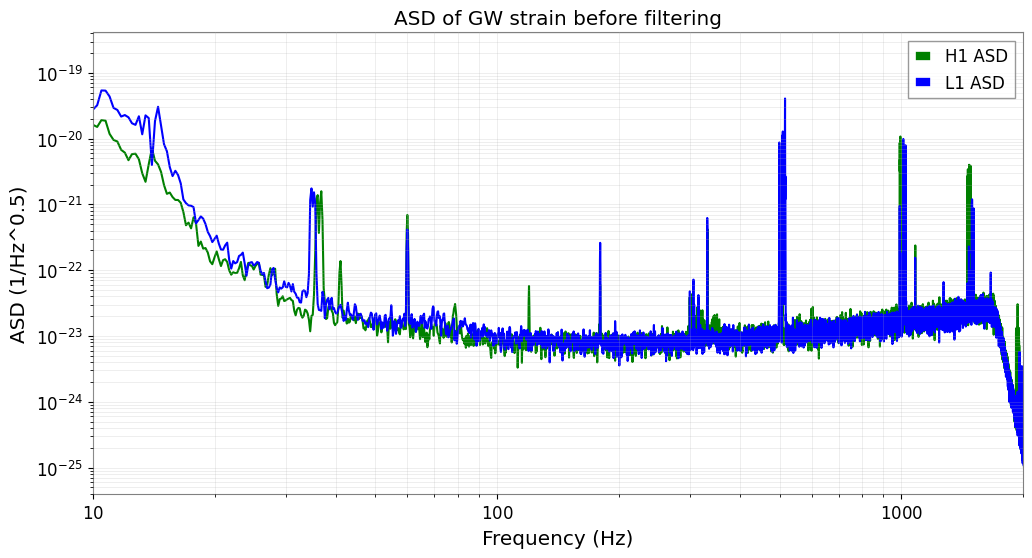

In [43]:
# PSD / ASD before whitening
t = h1.times.value - gps_event
h1_pre0 = h1_dc.copy()
l1_pre0 = l1_dc.copy()

h1_psd1 = h1_pre0.psd(method='welch', fftlength=4, overlap=2)
l1_psd1 = l1_pre0.psd(method='welch', fftlength=4, overlap=2)

plt.figure(figsize=(12, 6))
plt.loglog(h1_psd1.frequencies.value, h1_psd1.value, label='H1 PSD', color='green')
plt.title('PSD of H1 GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(l1_psd1.frequencies.value, l1_psd1.value, label='L1 PSD', color='blue')
plt.title('PSD of L1 GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(h1_psd1.frequencies.value, h1_psd1.value, label='H1 PSD', color='green')
plt.loglog(l1_psd1.frequencies.value, l1_psd1.value, label='L1 PSD', color='blue')
plt.title('PSD of GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.xlim(10,2000)
plt.show()

h1_asd1 = h1_pre0.asd(method='welch', fftlength=4, overlap=2)
l1_asd1 = l1_pre0.asd(method='welch', fftlength=4, overlap=2)

plt.figure(figsize=(12, 6))
plt.loglog(h1_asd1.frequencies.value, h1_asd1.value, label='H1 ASD', color='green')
plt.title('ASD of H1 GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(l1_asd1.frequencies.value, l1_asd1.value, label='L1 ASD', color='blue')
plt.title('ASD of L1 GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(h1_asd1.frequencies.value, h1_asd1.value, label='H1 ASD', color='green')
plt.loglog(l1_asd1.frequencies.value, l1_asd1.value, label='L1 ASD', color='blue')
plt.title('ASD of GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.xlim(10,2000)
plt.show()

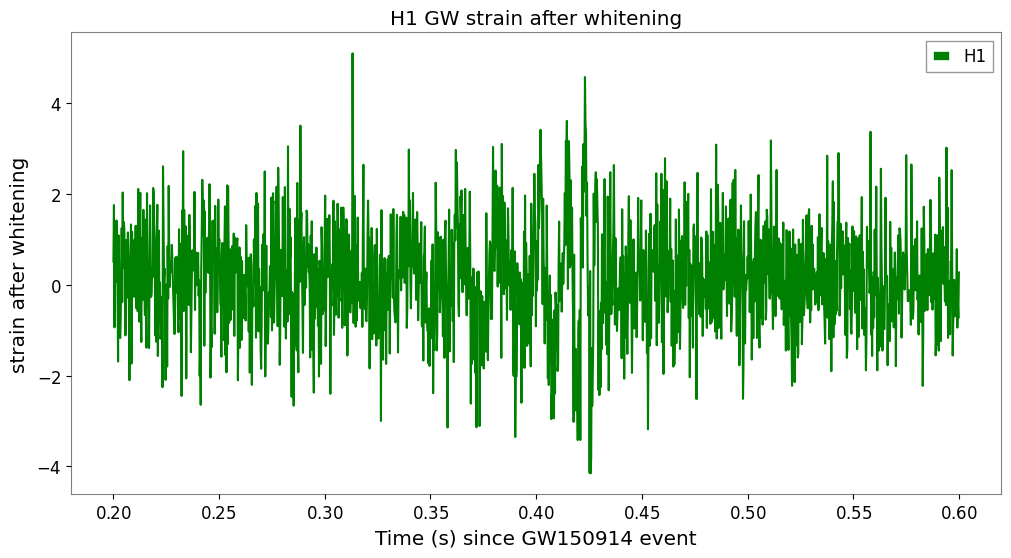

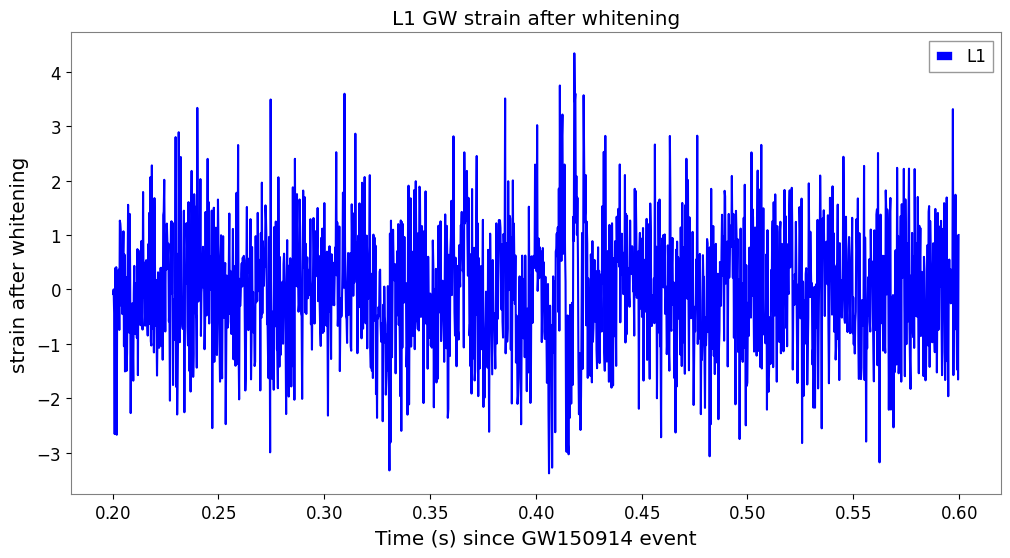

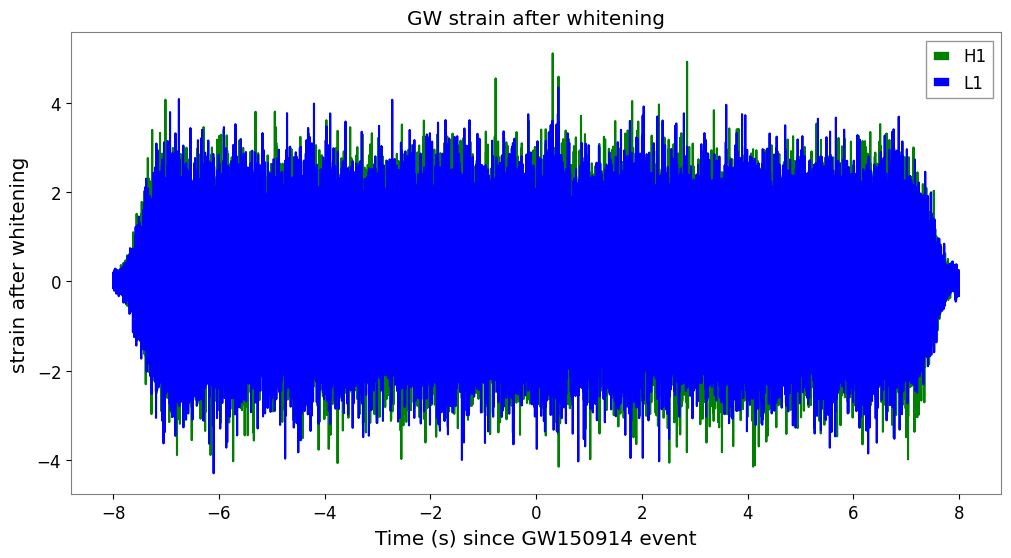

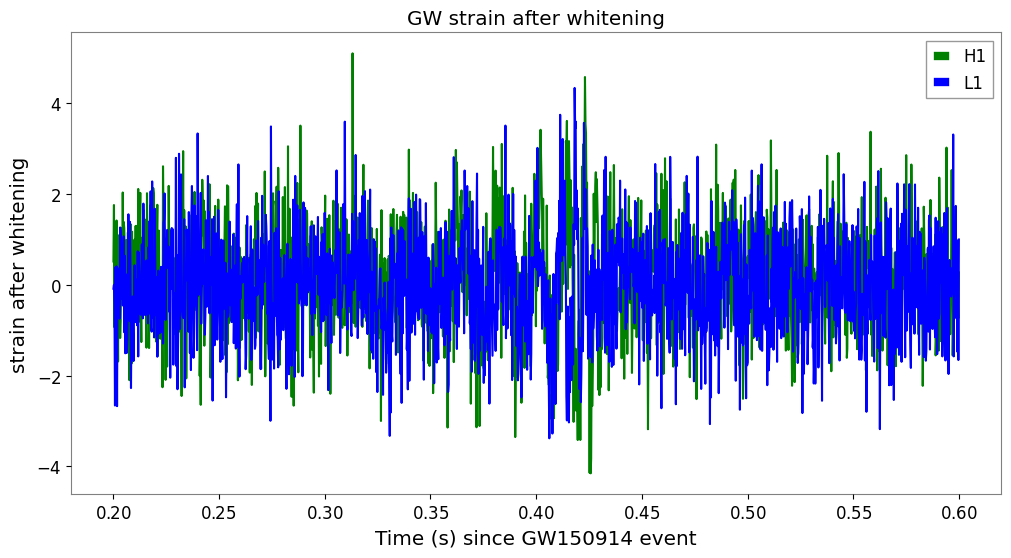

In [41]:
# whitening
t = h1.times.value - gps_event
h1_pre3 = h1_dc.copy()
l1_pre3 = l1_dc.copy()

h1_whiten = h1_pre3.whiten()
l1_whiten = l1_pre3.whiten()

mask = (t>0.2) & (t<0.6)

plt.figure(figsize=(12, 6))
plt.plot(t[mask],h1_whiten[mask],label='H1',color='green')
plt.title('H1 GW strain after whitening')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('strain after whitening')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(t[mask],l1_whiten[mask],label='L1',color='blue')
plt.title('L1 GW strain after whitening')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('strain after whitening')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(t, h1_whiten, label='H1', color='green')
plt.plot(t, l1_whiten, label='L1', color='blue')
plt.title('GW strain after whitening')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('strain after whitening')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(t[mask],h1_whiten[mask],label='H1',color='green')
plt.plot(t[mask],l1_whiten[mask],label='L1',color='blue')
plt.title('GW strain after whitening')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('strain after whitening')
plt.legend()
plt.grid()
plt.show()

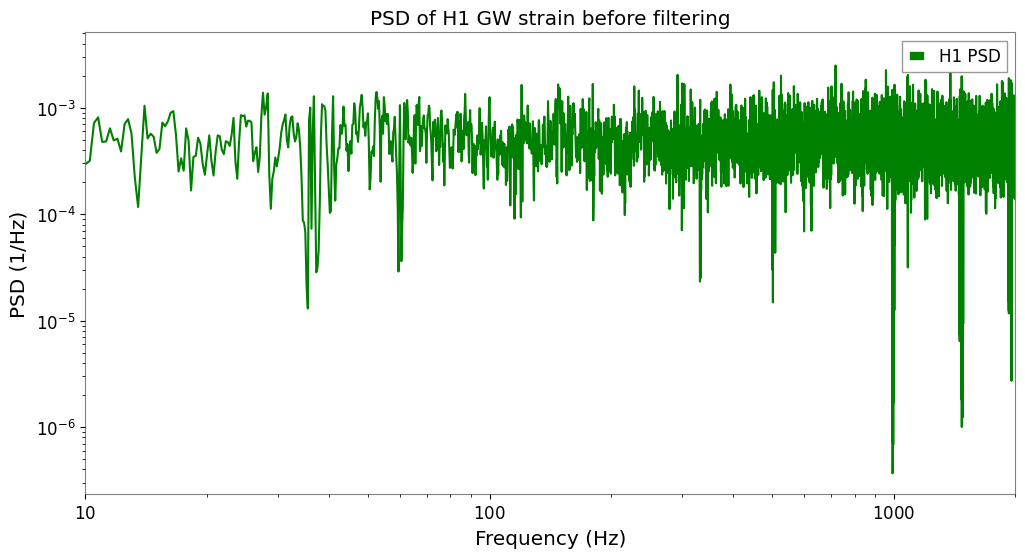

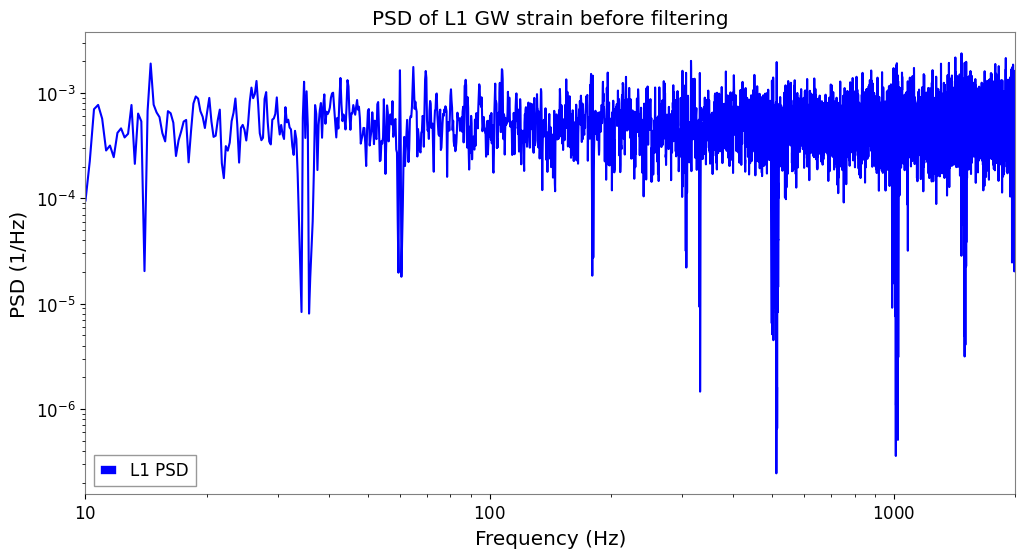

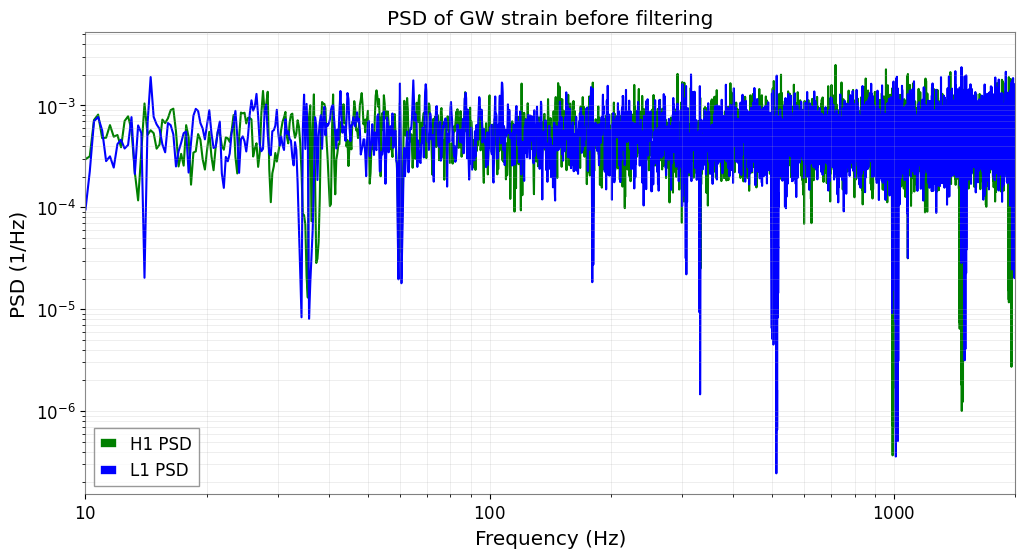

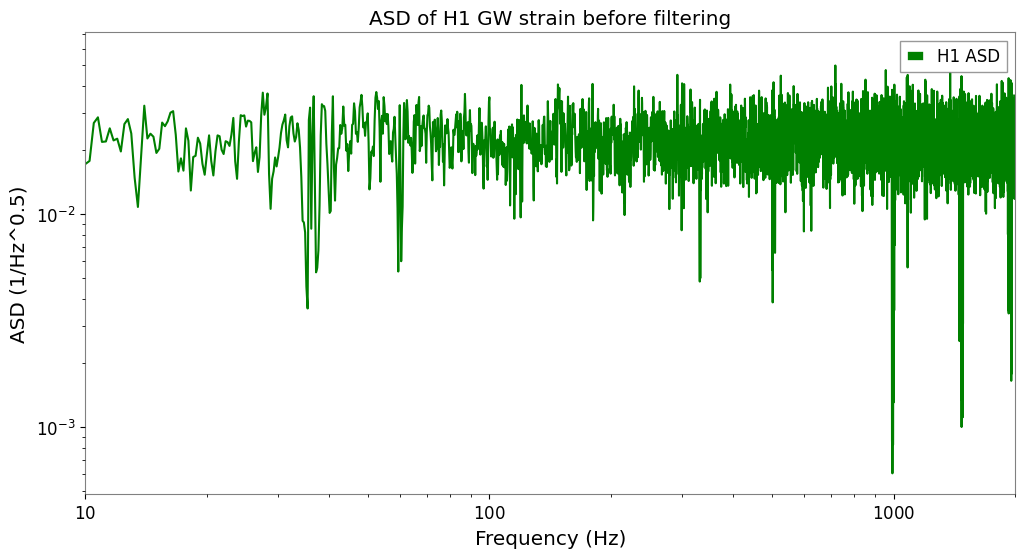

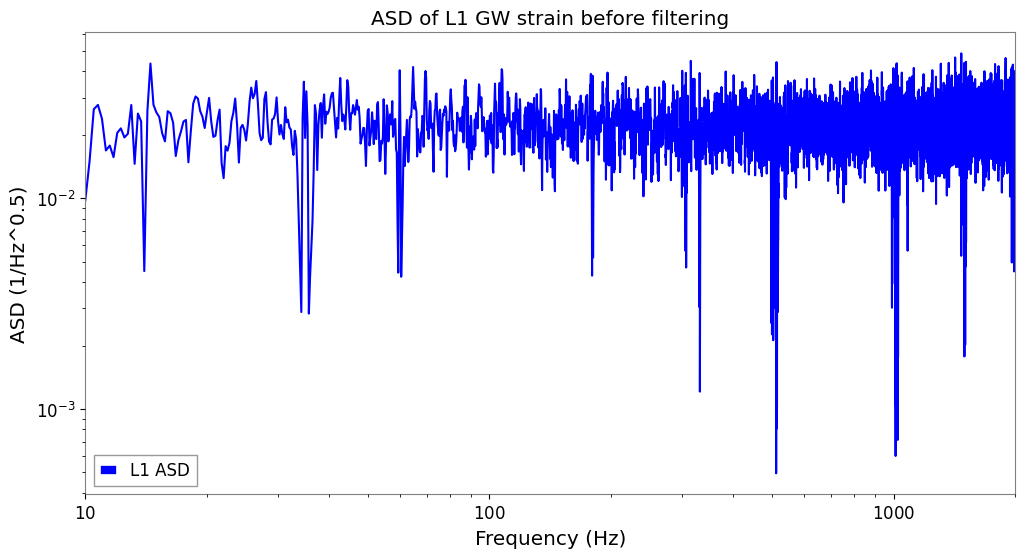

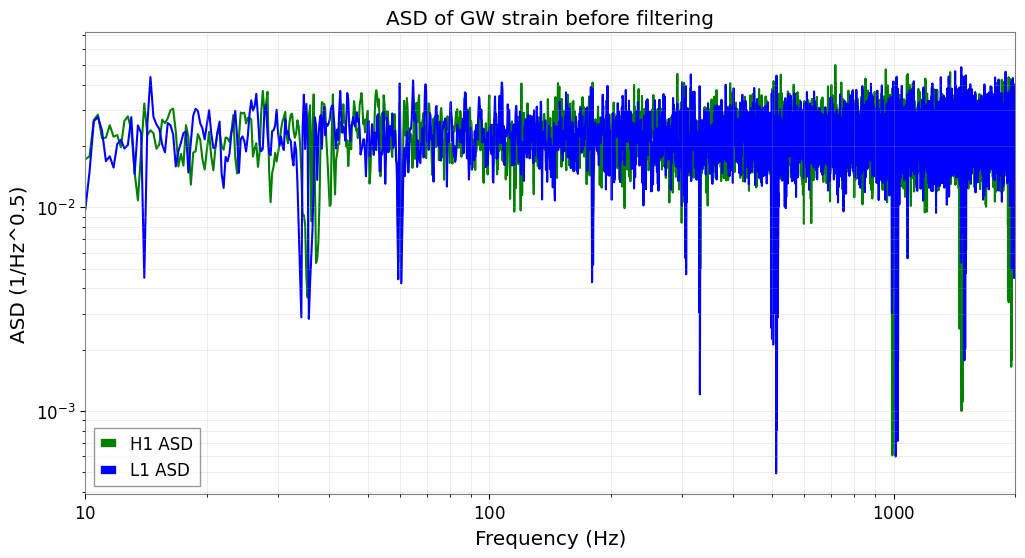

In [42]:
# PSD / ASD before filtering
t = h1.times.value - gps_event
h1_pre0 = h1_whiten.copy()
l1_pre0 = l1_whiten.copy()

h1_psd1 = h1_pre0.psd(method='welch', fftlength=4, overlap=2)
l1_psd1 = l1_pre0.psd(method='welch', fftlength=4, overlap=2)

plt.figure(figsize=(12, 6))
plt.loglog(h1_psd1.frequencies.value, h1_psd1.value, label='H1 PSD', color='green')
plt.title('PSD of H1 GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(l1_psd1.frequencies.value, l1_psd1.value, label='L1 PSD', color='blue')
plt.title('PSD of L1 GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(h1_psd1.frequencies.value, h1_psd1.value, label='H1 PSD', color='green')
plt.loglog(l1_psd1.frequencies.value, l1_psd1.value, label='L1 PSD', color='blue')
plt.title('PSD of GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.xlim(10,2000)
plt.show()

h1_asd1 = h1_pre0.asd(method='welch', fftlength=4, overlap=2)
l1_asd1 = l1_pre0.asd(method='welch', fftlength=4, overlap=2)

plt.figure(figsize=(12, 6))
plt.loglog(h1_asd1.frequencies.value, h1_asd1.value, label='H1 ASD', color='green')
plt.title('ASD of H1 GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(l1_asd1.frequencies.value, l1_asd1.value, label='L1 ASD', color='blue')
plt.title('ASD of L1 GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(h1_asd1.frequencies.value, h1_asd1.value, label='H1 ASD', color='green')
plt.loglog(l1_asd1.frequencies.value, l1_asd1.value, label='L1 ASD', color='blue')
plt.title('ASD of GW strain before filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.xlim(10,2000)
plt.show()

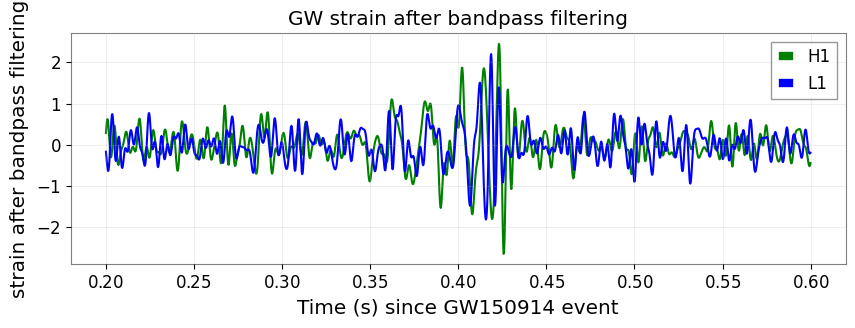

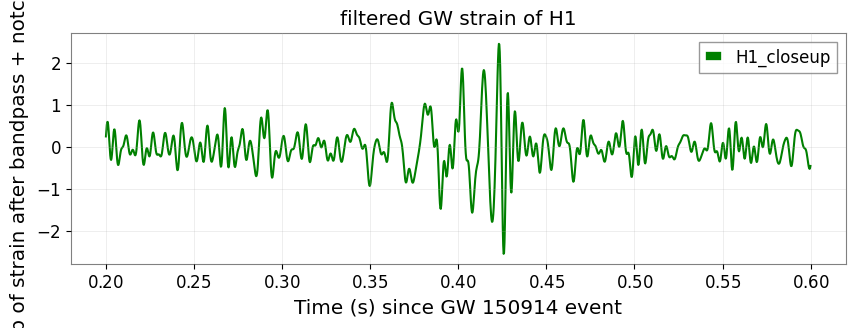

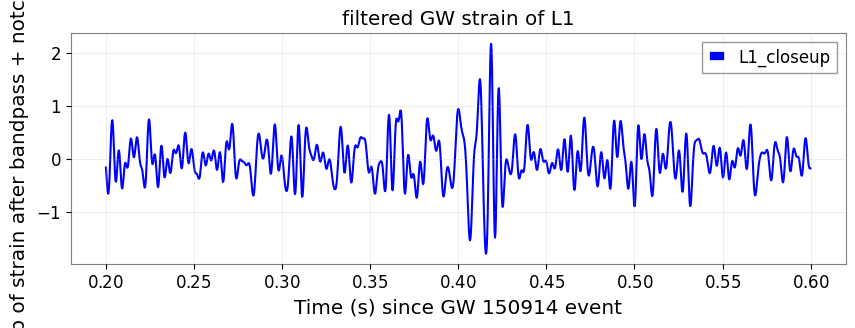

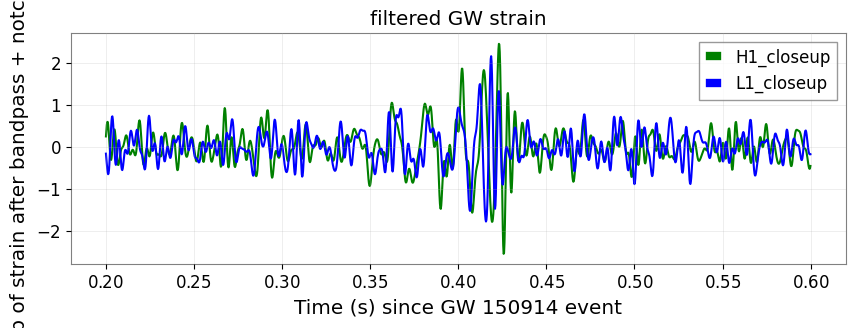

In [59]:
# bandpass / notch filters
t = h1.times.value - gps_event
h1_pre1 = h1_whiten.copy()
l1_pre1 = l1_whiten.copy()

h1_bp = h1_pre1.bandpass(40,300)
l1_bp = l1_pre1.bandpass(40,300)

mask = (t>0.2) & (t<0.6)
plt.figure(figsize=(10, 3))
plt.plot(t[mask],h1_bp[mask], label='H1', color='green')
plt.plot(t[mask],l1_bp[mask], label='L1', color='blue')
#plt.plot(t, h1_bp, label='H1', color='red')
#plt.plot(t, l1_bp, label='L1', color='blue')
plt.title('GW strain after bandpass filtering')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('strain after bandpass filtering')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

h1_pre2 = h1_bp.copy()
l1_pre2 = l1_bp.copy()

#h1_notch = h1_pre2.notch_fir([60,120,180])
#l1_notch = l1_pre2.notch_fir([60,180])
h1_notch = h1_pre2.notch(60).notch(120).notch(180)
l1_notch = l1_pre2.notch(60).notch(180)
#h1_notch = h1_notch.notch(120)
#h1_notch = h1_notch.notch(180)
#l1_notch = l1_pre2.notch(60)
#l1_notch = l1_notch.notch(180)

#plt.figure(figsize=(12, 6))
#plt.plot(t, h1_notch, label='H1', color='red')
#plt.plot(t, l1_notch, label='L1', color='blue')
#plt.title('GW strain after bandpass + notch filtering')
#plt.xlabel('Time (s) since GW150914 event')
#plt.ylabel('strain after bandpass + notch filtering')
#plt.legend()
#plt.grid(True, alpha=0.3)
#plt.show()

mask = (t>0.2) & (t<0.6)
plt.figure(figsize=(10, 3))
plt.plot(t[mask], h1_notch[mask], label='H1_closeup', color='green')
#plt.plot(t,h1_notch,label='H1', color='green')
plt.title('filtered GW strain of H1')
plt.xlabel('Time (s) since GW 150914 event')
plt.ylabel('closeup of strain after bandpass + notch filtering')
#plt.ylim(-5e-21,5e-21)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#mask = (t>0.2) & (t<0.6)
plt.figure(figsize=(10, 3))
plt.plot(t[mask], l1_notch[mask], label='L1_closeup', color='blue')
#plt.plot(t,l1_notch,label='L1', color='blue')
plt.title('filtered GW strain of L1')
plt.xlabel('Time (s) since GW 150914 event')
plt.ylabel('closeup of strain after bandpass + notch filtering')
#plt.ylim(-5e-21,5e-21)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#mask = (t>0.2) & (t<0.6)
plt.figure(figsize=(10, 3))
plt.plot(t[mask], h1_notch[mask], label='H1_closeup', color='green')
plt.plot(t[mask], l1_notch[mask], label='L1_closeup', color='blue')
#plt.plot(t,h1_notch,label='H1', color='green')
#plt.plot(t,l1_notch,label='L1', color='blue')
plt.title('filtered GW strain')
plt.xlabel('Time (s) since GW 150914 event')
plt.ylabel('closeup of strain after bandpass + notch filtering')
#plt.ylim(-5e-21,5e-21)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

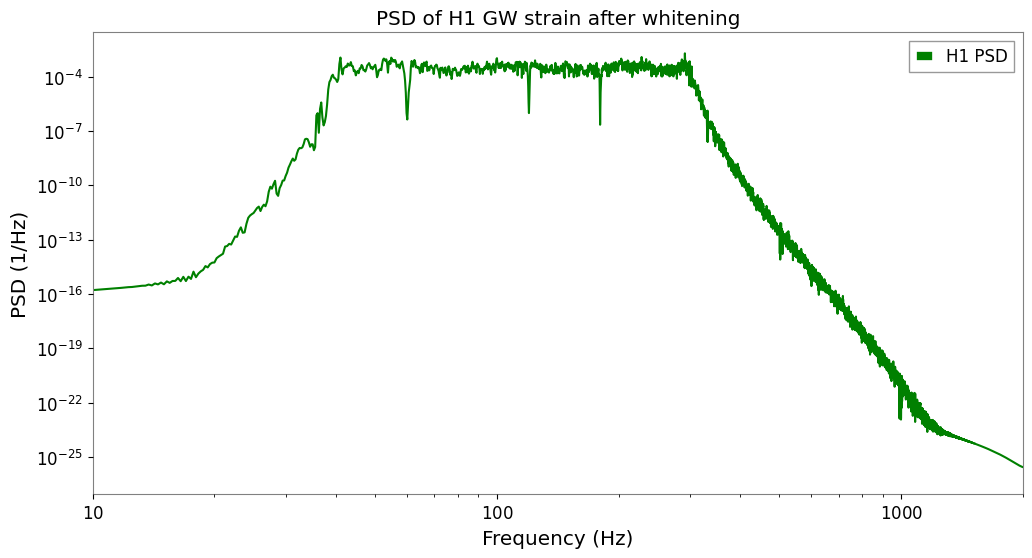

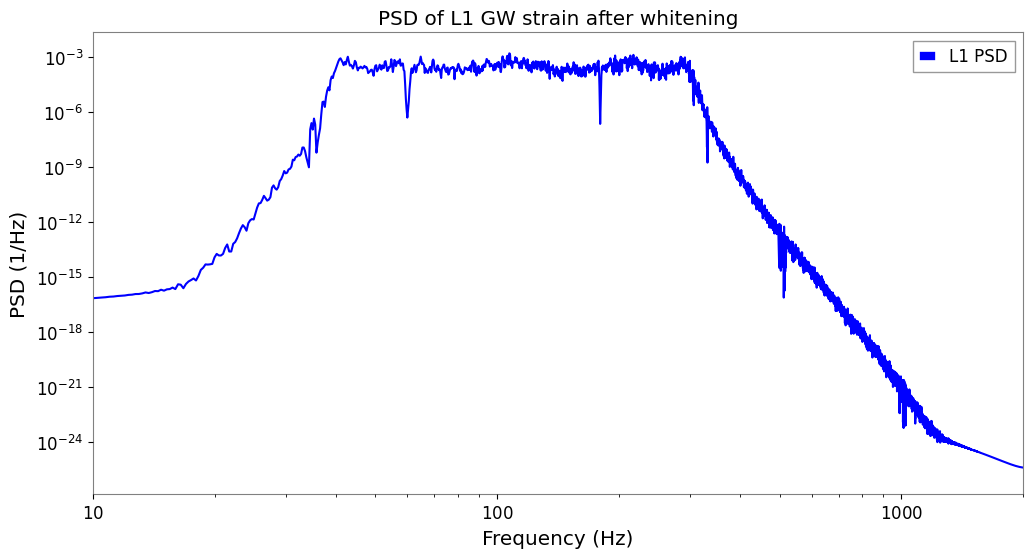

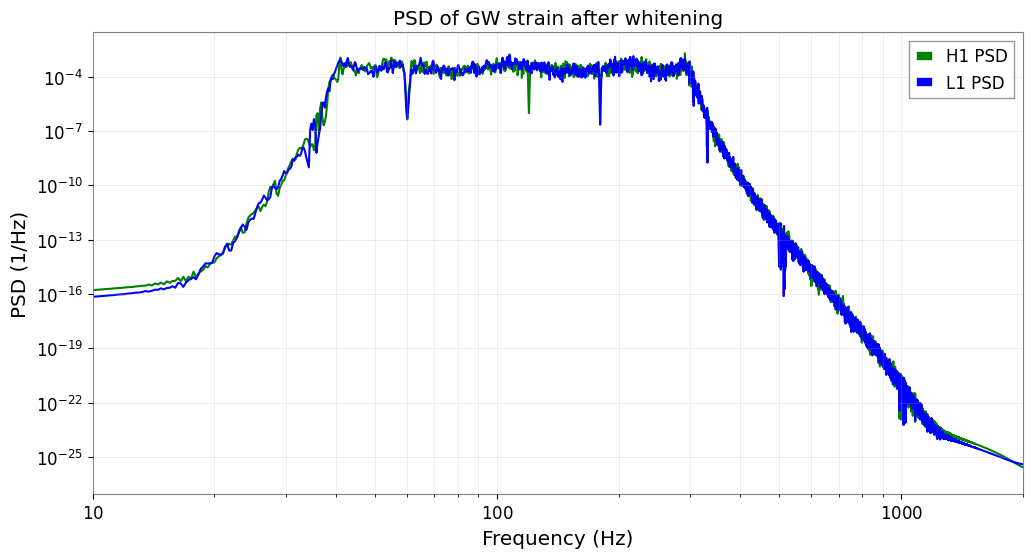

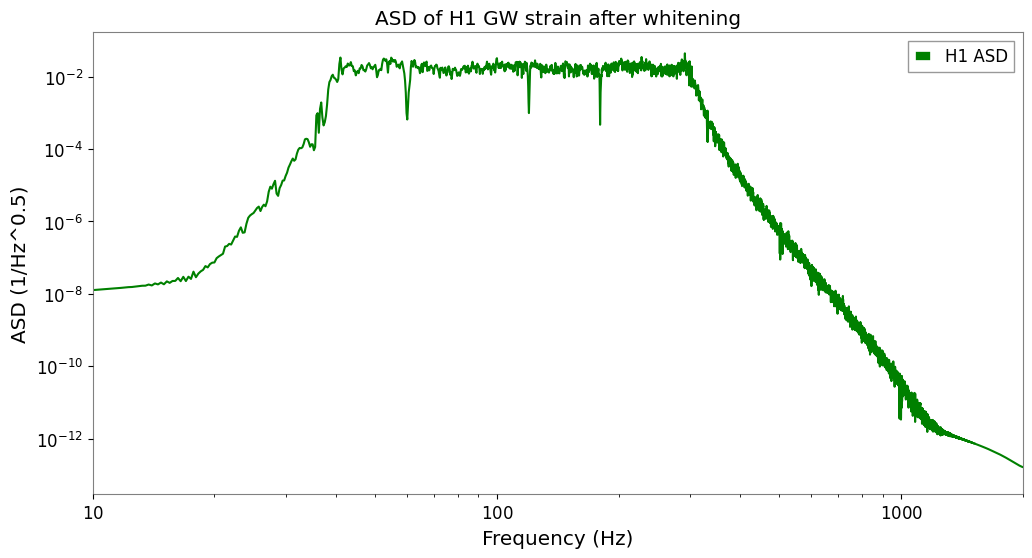

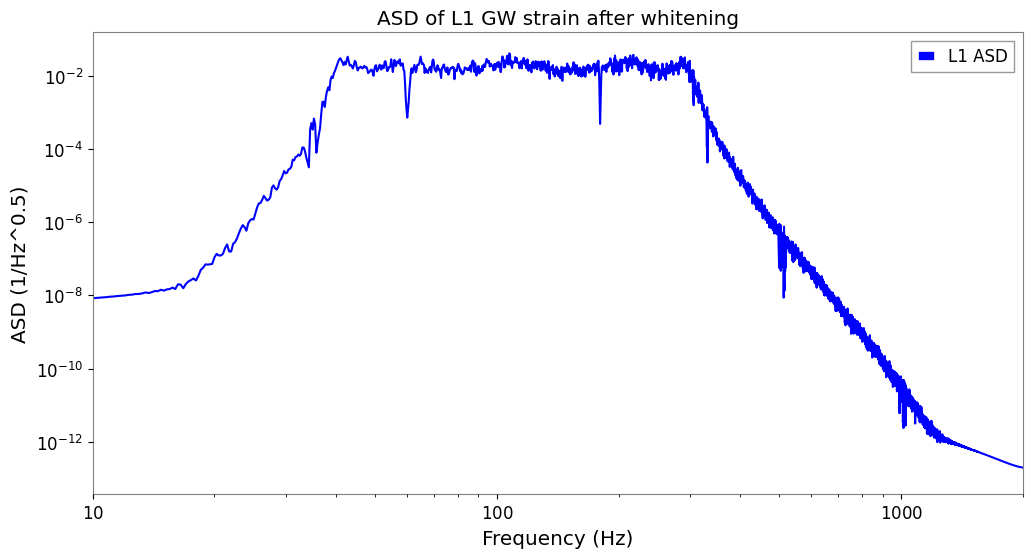

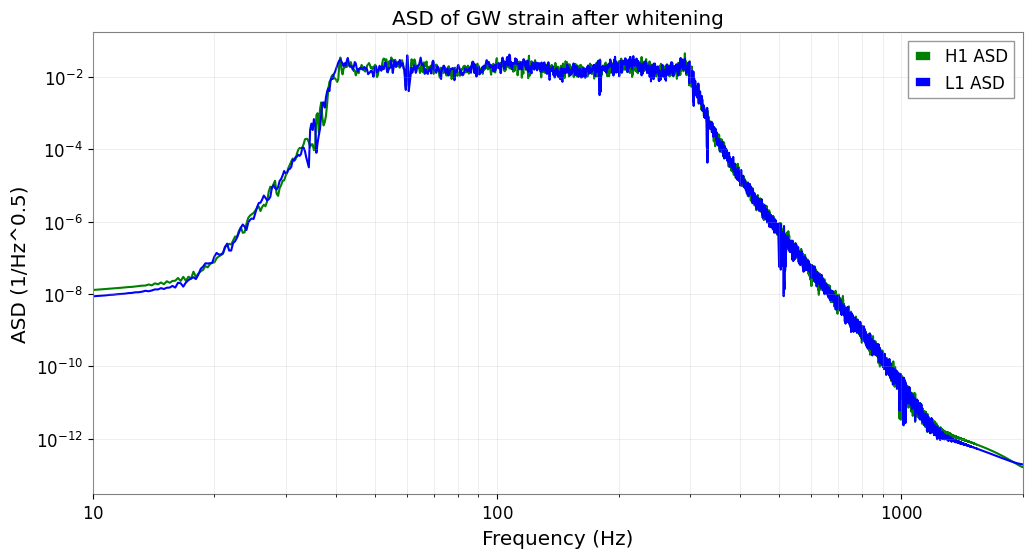

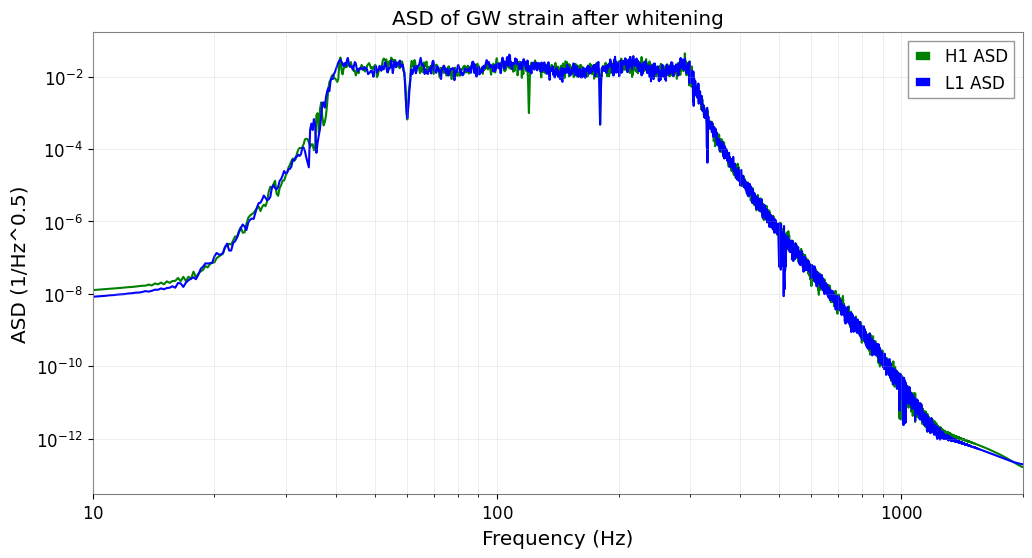

In [64]:
# PSD / ASD after filtering
t = h1.times.value - gps_event
h1_pre4 = h1_notch.copy()
l1_pre4 = l1_notch.copy()

h1_psd2 = h1_pre4.psd(method='welch', fftlength=4, overlap=2)
l1_psd2 = l1_pre4.psd(method='welch', fftlength=4, overlap=2)

plt.figure(figsize=(12, 6))
plt.loglog(h1_psd2.frequencies.value, h1_psd2.value, label='H1 PSD', color='green')
plt.title('PSD of H1 GW strain after filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(l1_psd2.frequencies.value, l1_psd2.value, label='L1 PSD', color='blue')
plt.title('PSD of L1 GW strain after filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(h1_psd2.frequencies.value, h1_psd2.value, label='H1 PSD', color='green')
plt.loglog(l1_psd2.frequencies.value, l1_psd2.value, label='L1 PSD', color='blue')
plt.title('PSD of GW strain after filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (1/Hz)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.xlim(10,2000)
plt.show()

h1_asd2 = h1_pre4.asd(method='welch', fftlength=4, overlap=2)
l1_asd2 = l1_pre4.asd(method='welch', fftlength=4, overlap=2)

plt.figure(figsize=(12, 6))
plt.loglog(h1_asd2.frequencies.value, h1_asd2.value, label='H1 ASD', color='green')
plt.title('ASD of H1 GW strain after filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(l1_asd2.frequencies.value, l1_asd2.value, label='L1 ASD', color='blue')
plt.title('ASD of L1 GW strain after filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid()
plt.xlim(10,2000)
plt.show()

h1_asd3 = h1_pre2.asd(method='welch', fftlength=4, overlap=2)
l1_asd3 = l1_pre2.asd(method='welch', fftlength=4, overlap=2)

plt.figure(figsize=(12, 6))
plt.loglog(h1_asd3.frequencies.value, h1_asd3.value, label='H1 ASD', color='green')
plt.loglog(l1_asd3.frequencies.value, l1_asd3.value, label='L1 ASD', color='blue')
plt.title('ASD of GW strain after bandpass filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.xlim(10,2000)
plt.show()

plt.figure(figsize=(12, 6))
plt.loglog(h1_asd2.frequencies.value, h1_asd2.value, label='H1 ASD', color='green')
plt.loglog(l1_asd2.frequencies.value, l1_asd2.value, label='L1 ASD', color='blue')
plt.title('ASD of GW strain after notch filtering')
plt.xlabel('Frequency (Hz)')
plt.ylabel('ASD (1/Hz^0.5)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.xlim(10,2000)
plt.show()

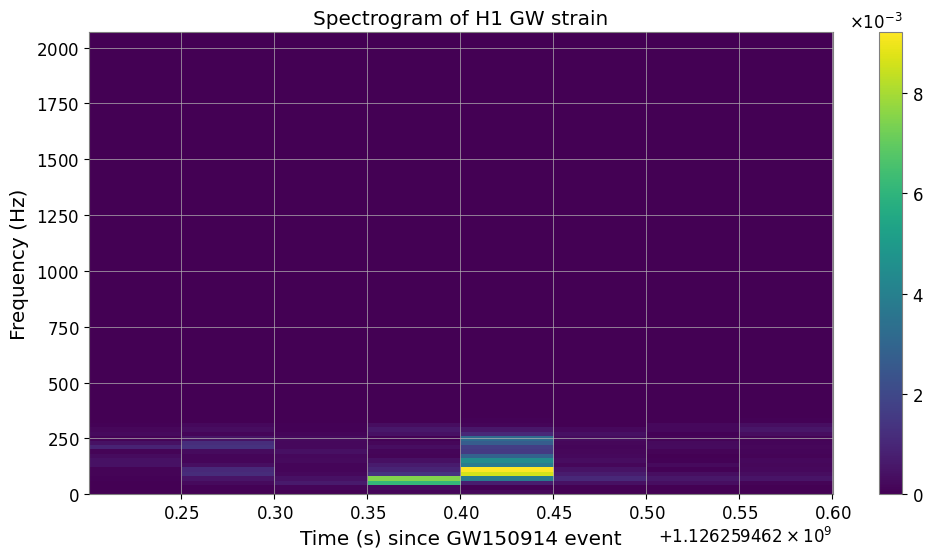

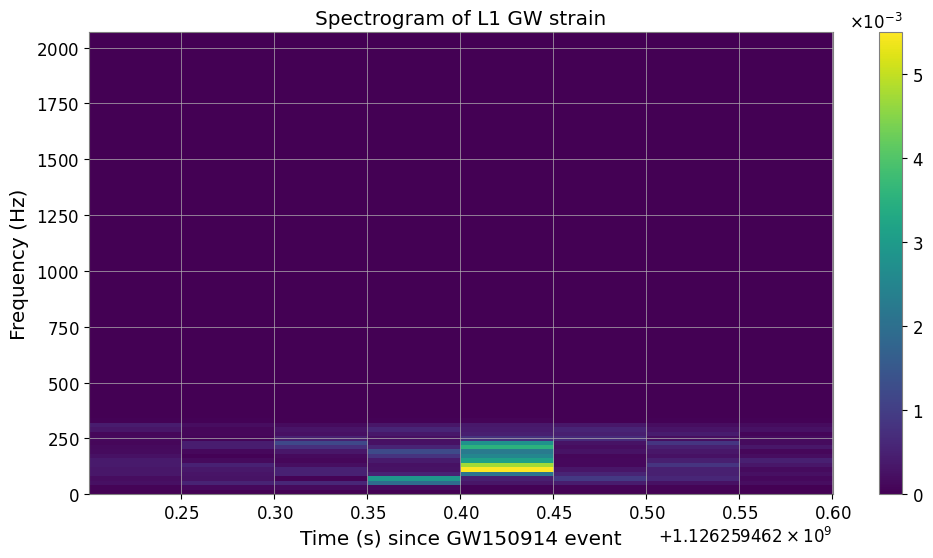

In [70]:
from astropy.units.misc import sp
# spectrogram
t = h1.times.value - gps_event
h1_pre5 = h1_notch.copy()
l1_pre5 = l1_notch.copy()

mask = (t>0.2) & (t<0.6)
h1_zoom = h1_pre5[mask]
l1_zoom = l1_pre5[mask]

# The original fftlength (4096 seconds) was much larger than the duration of h1_zoom (0.4 seconds),
# leading to the ValueError. Adjusting fftlength and overlap to be suitable for
# the 0.4-second data segment.
# For example, use fftlength of 0.05 seconds (approx 200 samples) and 50% overlap (0.025 seconds).
fft_length = 0.05
# To satisfy `fftlength <= stride` constraint, set stride equal to fft_length
stride = fft_length

h1_spec = h1_zoom.spectrogram(fftlength=fft_length, stride=stride)
l1_spec = l1_zoom.spectrogram(fftlength=fft_length, stride=stride)

plt.figure(figsize=(12, 6))
plt.pcolormesh(h1_spec)
plt.title('Spectrogram of H1 GW strain')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('Frequency (Hz)')
plt.colorbar()
plt.show()

plt.figure(figsize=(12, 6))
plt.pcolormesh(l1_spec)
plt.title('Spectrogram of L1 GW strain')
plt.xlabel('Time (s) since GW150914 event')
plt.ylabel('Frequency (Hz)')
plt.colorbar()
plt.show()

In [ ]:
# Q-transform
t = h1.times.value - gps_event

h1_q = h1_pre5.q_transform()
l1_q = l1_pre5.q_transform()

plt.figure(figsize=(12, 6))


In [ ]:
# matched filtering 은 제외
t = h1.times.value - gps_event
h1_pre6 = h1_notch.copy()
l1_pre6 = l1_notch.copy()

h1_matched = h1_pre6.matched_filter([])
l1_matched = l1_pre6.matched_filter([])

plt.figure(figsize=(12, 6))


In [ ]:
# SNR 도 제외
t = h1.times.value - gps_event

h1_snr = h1_pre5.snr()
l1_snr = l1_pre5.snr()

plt.figure(figsize=(12, 6))
